# Notebook 3 – Data Quality Assessment

# Objective

The objective of this notebook is to assess the quality of the Titanic dataset by identifying missing values, duplicate records, invalid values, incorrect data types, unexpected values, empty strings, and null-like values.

# Dataset
Titanic passenger dataset.

# Topics Covered
    
Missing value counts and percentages

Missing values by column and patterns

Duplicate and potential duplicate records

Negative and impossible values

Incorrect categories and data types

Empty strings and null-like values

In [1]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 891
Columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print("Missing values in each column:")
display(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Total missing values:
866


In [3]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


In [4]:
print("Rows containing at least one missing value:")
display(df[df.isnull().any(axis=1)].head(10))

print("\nNumber of rows with missing values:")
print(df.isnull().any(axis=1).sum())

print("\nMissing-value pattern by row:")
display(df.isnull().head(10))

Rows containing at least one missing value:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C
12,13,0,3,"Saundercock, Mr. William Henry",male,20.0,0,0,A/5. 2151,8.0500,NaN,S
13,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,347082,31.2750,NaN,S
14,15,0,3,"Vestrom, Miss. Hulda Amanda Adolfina",female,14.0,0,0,350406,7.8542,NaN,S



Number of rows with missing values:
708

Missing-value pattern by row:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
5,False,False,False,False,False,True,False,False,False,False,True,False
6,False,False,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False,True,False
8,False,False,False,False,False,False,False,False,False,False,True,False
9,False,False,False,False,False,False,False,False,False,False,True,False


In [5]:
print("Number of completely duplicated rows:")
print(df.duplicated().sum())

print("\nCompletely duplicated records:")
display(df[df.duplicated(keep=False)])

Number of completely duplicated rows:
0

Completely duplicated records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [6]:
print("Duplicate PassengerId values:")
print(df["PassengerId"].duplicated().sum())

print("\nRepeated passenger IDs:")
display(df[df["PassengerId"].duplicated(keep=False)])

Duplicate PassengerId values:
0

Repeated passenger IDs:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [8]:
# Check negative values in numerical columns
numerical_df = df.select_dtypes(include="number")

print("Negative value counts:")
display((numerical_df < 0).sum())

# Check impossible ages
if "Age" in df.columns:
    print("\nInvalid ages (below 0 or above 120):")
    display(df[(df["Age"] < 0) | (df["Age"] > 120)])

# Check invalid passenger fares
if "Fare" in df.columns:
    print("\nNegative fares:")
    display(df[df["Fare"] < 0])
    

Negative value counts:


PassengerId    0
Survived       0
Pclass         0
Age            0
SibSp          0
Parch          0
Fare           0
dtype: int64


Invalid ages (below 0 or above 120):


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked



Negative fares:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [9]:
print("Unique values in Sex:")
print(df["Sex"].unique())

print("\nUnique values in Embarked:")
print(df["Embarked"].unique())

print("\nUnique values in Pclass:")
print(df["Pclass"].unique())

# Expected values
print("\nUnexpected Sex values:")
display(df[~df["Sex"].isin(["male", "female"])])

print("\nUnexpected Pclass values:")
display(df[~df["Pclass"].isin([1, 2, 3])])

Unique values in Sex:
<ArrowStringArray>
['male', 'female']
Length: 2, dtype: str

Unique values in Embarked:
<ArrowStringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

Unique values in Pclass:
[3 1 2]

Unexpected Sex values:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked



Unexpected Pclass values:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [10]:
print("Checking notebook...")

try:
    print("DataFrame exists:", "df" in globals())

    import pandas as pd
    print("Pandas is working:", pd.__version__)

    if "df" in globals():
        print("Dataset shape:", df.shape)
    else:
        print("The dataset has not been loaded in this kernel.")

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error details:", str(e))

Checking notebook...
DataFrame exists: True
Pandas is working: 3.0.3
Dataset shape: (891, 12)


In [11]:
print("Notebook 3 is running.")
print("Python calculation test:", 10 + 5)


Notebook 3 is running.
Python calculation test: 15


In [12]:
print("DataFrame exists:", "df" in globals())

DataFrame exists: True


In [13]:
print("Checking dataset...")

if "df" in globals():
    print("Dataset is available.")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
else:
    print("Dataset is not loaded. Run the dataset-loading cell first.")

Checking dataset...
Dataset is available.
Rows: 891
Columns: 12


In [14]:
print("Column names and data types:")

for column in df.columns:
    print(column, ":", df[column].dtype)

Column names and data types:
PassengerId : int64
Survived : int64
Pclass : int64
Name : str
Sex : str
Age : float64
SibSp : int64
Parch : int64
Ticket : str
Fare : float64
Cabin : str
Embarked : str


In [15]:
print("Missing values in each column:")

for column in df.columns:
    print(column, ":", df[column].isnull().sum())

Missing values in each column:
PassengerId : 0
Survived : 0
Pclass : 0
Name : 0
Sex : 0
Age : 177
SibSp : 0
Parch : 0
Ticket : 0
Fare : 0
Cabin : 687
Embarked : 2


In [16]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [17]:
# Check negative values in numerical columns
numerical_df = df.select_dtypes(include="number")

print("Negative values in each numerical column:")
display((numerical_df < 0).sum())

Negative values in each numerical column:


PassengerId    0
Survived       0
Pclass         0
Age            0
SibSp          0
Parch          0
Fare           0
dtype: int64

In [18]:
print("Invalid ages (below 0 or above 120):")
display(df[(df["Age"] < 0) | (df["Age"] > 120)])

print("Negative fares:")
display(df[df["Fare"] < 0])

Invalid ages (below 0 or above 120):


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


Negative fares:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [19]:
print("Sex categories:")
print(df["Sex"].value_counts(dropna=False))

print("\nPassenger class categories:")
print(df["Pclass"].value_counts(dropna=False))

print("\nEmbarkation categories:")
print(df["Embarked"].value_counts(dropna=False))


Sex categories:
Sex
male      577
female    314
Name: count, dtype: int64

Passenger class categories:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Embarkation categories:
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


In [20]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [21]:
missing = df.isnull().sum()

print("Missing values before cleaning:")
display(missing[missing > 0])

Missing values before cleaning:


Age         177
Cabin       687
Embarked      2
dtype: int64

In [22]:
# Fill missing ages with the median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing embarkation ports with the most frequent value
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin because many values are missing
df = df.drop(columns=["Cabin"])

In [23]:
print("Dataset shape after cleaning:", df.shape)
print("\nRemaining missing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

Dataset shape after cleaning: (891, 11)

Remaining missing values:


Series([], dtype: int64)

In [24]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [25]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)


Dataset shape after removing duplicates: (891, 11)


In [26]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFinal dataset shape:", df.shape)

display(df.head())

Missing values:


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


Duplicate rows: 0

Final dataset shape: (891, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [27]:
df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [28]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("titanic_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (891, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [29]:
print("Dataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 111.0 KB

Numerical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [30]:
print("Survival counts:")
display(df["Survived"].value_counts())

print("\nSurvival percentages:")
display((df["Survived"].value_counts(normalize=True) * 100).round(2))

Survival counts:


Survived
0    549
1    342
Name: count, dtype: int64


Survival percentages:


Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

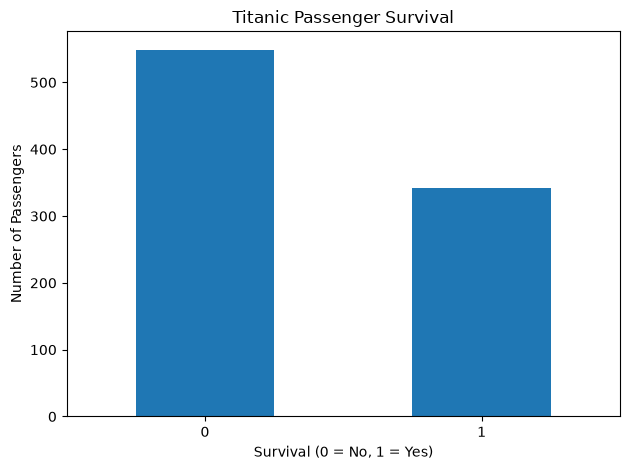

In [31]:
df["Survived"].value_counts().sort_index().plot(
    kind="bar",
    title="Titanic Passenger Survival"
)

plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Survived,0,1
Sex,,
female,81,233
male,468,109


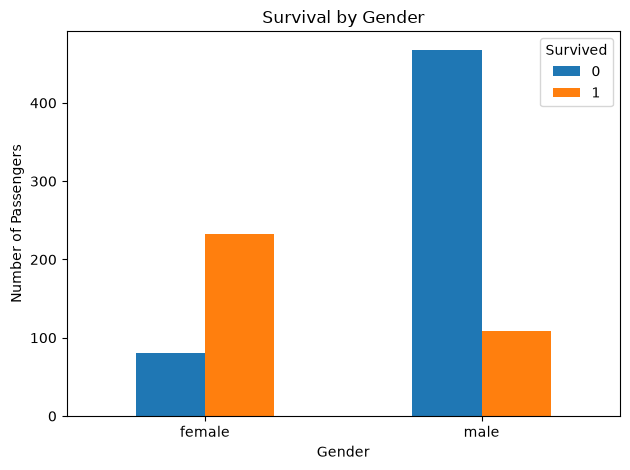

In [32]:
survival_by_gender = pd.crosstab(df["Sex"], df["Survived"])
display(survival_by_gender)

survival_by_gender.plot(
    kind="bar",
    title="Survival by Gender"
)

plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Survival counts by passenger class:


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


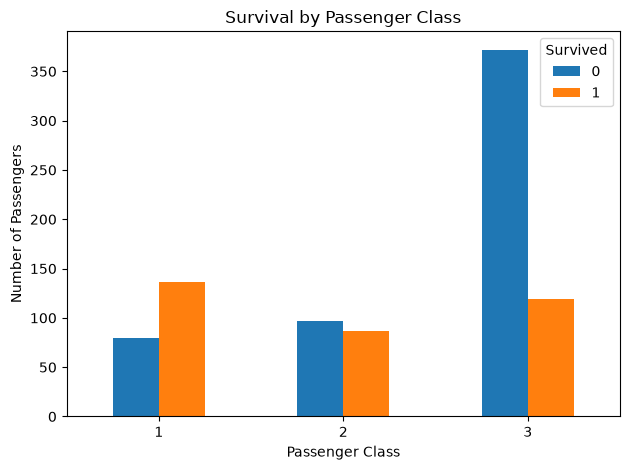

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

survival_by_class = pd.crosstab(df["Pclass"], df["Survived"])

print("Survival counts by passenger class:")
display(survival_by_class)

survival_by_class.plot(
    kind="bar",
    title="Survival by Passenger Class"
)

plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Age statistics:


count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64

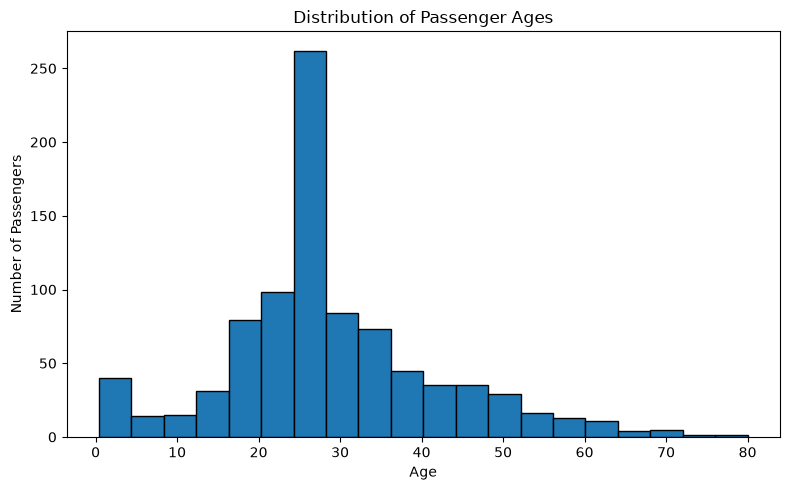

In [34]:
print("Age statistics:")
display(df["Age"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["Age"], bins=20, edgecolor="black")
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

Fare statistics:


count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

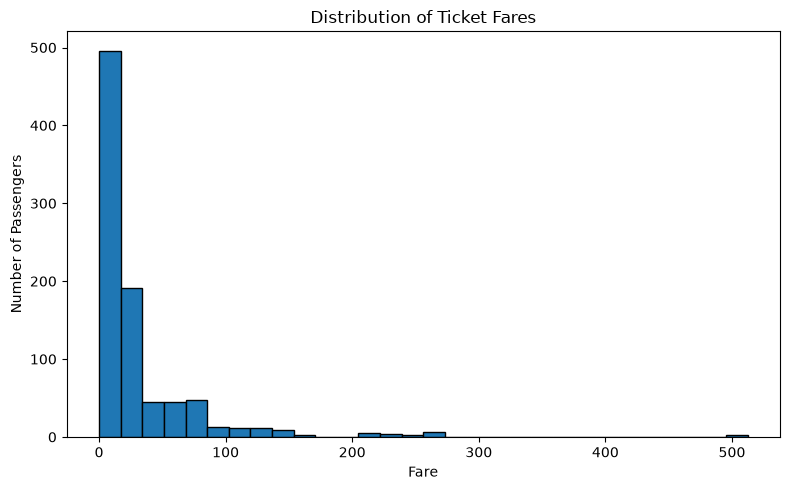

In [35]:
print("Fare statistics:")
display(df["Fare"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["Fare"], bins=30, edgecolor="black")
plt.title("Distribution of Ticket Fares")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

In [36]:
survival_rate = df.groupby(["Sex", "Pclass"])["Survived"].mean() * 100

print("Survival percentage by gender and passenger class:")
display(survival_rate.round(2))

Survival percentage by gender and passenger class:


Sex     Pclass
female  1         96.81
        2         92.11
        3         50.00
male    1         36.89
        2         15.74
        3         13.54
Name: Survived, dtype: float64

In [37]:
import pandas as pd
import numpy as np

df = pd.read_csv("titanic_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [38]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

display(df[["SibSp", "Parch", "FamilySize"]].head(10))

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


In [39]:
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

display(df[["FamilySize", "IsAlone"]].head(10))

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1
5,1,1
6,1,1
7,5,0
8,3,0
9,2,0


In [40]:
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.", expand=False)

print("Passenger titles:")
display(df["Title"].value_counts())

Passenger titles:


Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [41]:
df = df.drop(
    columns=["PassengerId", "Name", "Ticket"],
    errors="ignore"
)

print("Columns after feature engineering:")
print(df.columns.tolist())

display(df.head())

Columns after feature engineering:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'Title']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
0,0,3,male,22.0,1,0,7.2500,S,2,0,Mr
1,1,1,female,38.0,1,0,71.2833,C,2,0,Mrs
2,1,3,female,26.0,0,0,7.9250,S,1,1,Miss
3,1,1,female,35.0,1,0,53.1000,S,2,0,Mrs
4,0,3,male,35.0,0,0,8.0500,S,1,1,Mr


In [42]:
df.to_csv("titanic_feature_engineered.csv", index=False)

print("Feature-engineered dataset saved successfully!")
print("Final shape:", df.shape)

Feature-engineered dataset saved successfully!
Final shape: (891, 11)


In [43]:
import pandas as pd
import numpy as np

df = pd.read_csv("titanic_feature_engineered.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 11)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
0,0,3,male,22.0,1,0,7.2500,S,2,0,Mr
1,1,1,female,38.0,1,0,71.2833,C,2,0,Mrs
2,1,3,female,26.0,0,0,7.9250,S,1,1,Miss
3,1,1,female,35.0,1,0,53.1000,S,2,0,Mrs
4,0,3,male,35.0,0,0,8.0500,S,1,1,Mr


In [44]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (891, 10)
Target shape: (891,)


In [45]:
print("Is df defined?", "df" in globals())
print("Is X defined?", "X" in globals())

if "df" in globals():
    print("Dataset columns:", df.columns.tolist())

Is df defined? True
Is X defined? True
Dataset columns: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'Title']


In [46]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Load the feature-engineered dataset
df = pd.read_csv("titanic_feature_engineered.csv")

# Separate features and target
X = df.drop(columns=["Survived"])
y = df["Survived"]

# Convert categorical columns to numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Replace infinite values and handle any remaining missing values
X = X.replace([float("inf"), float("-inf")], float("nan"))
X = X.fillna(X.median())

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model trained successfully!
Accuracy: 83.8 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87       110
           1       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



Confusion Matrix:
[[98 12]
 [17 52]]


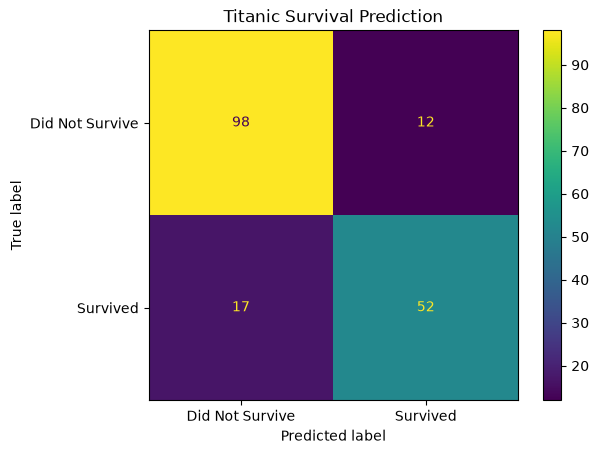

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot()
plt.title("Titanic Survival Prediction")
plt.show()

In [48]:
import joblib

joblib.dump(model, "titanic_survival_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [49]:
import pandas as pd

# Check that the prediction variables exist
print("y_test available:", "y_test" in globals())
print("y_pred available:", "y_pred" in globals())

# Create and save predictions
results = pd.DataFrame({
    "Actual_Survival": list(y_test),
    "Predicted_Survival": list(y_pred)
})

results.to_csv("titanic_predictions.csv", index=False)

print("Predictions saved successfully!")
print(results.head(10))

y_test available: True
y_pred available: True
Predictions saved successfully!
   Actual_Survival  Predicted_Survival
0                0                   0
1                0                   0
2                1                   0
3                0                   0
4                1                   1
5                1                   1
6                1                   1
7                0                   1
8                0                   0
9                0                   0


In [50]:
print("Pandas loaded:", "pd" in globals())
print("Test data available:", "y_test" in globals())
print("Predictions available:", "y_pred" in globals())

if "y_test" in globals():
    print("Number of test records:", len(y_test))

if "y_pred" in globals():
    print("Number of predictions:", len(y_pred))

Pandas loaded: True
Test data available: True
Predictions available: True
Number of test records: 179
Number of predictions: 179


# Titanic Survival Prediction
# Project Overview
This project uses machine learning to predict whether a Titanic passenger survived based on passenger information such as age, gender, passenger class, and family size.

# Objectives
Understand and inspect the Titanic dataset.
    
Identify and handle data-quality issues.
    
Perform exploratory data analysis (EDA).
    
Engineer useful features.
    
Encode categorical variables.
    
Train and evaluate a Logistic Regression model.
    
# Technologies Used
    
Python
    
Jupyter Notebook
    
Pandas and NumPy
    
Matplotlib
    
Scikit-learn
    
# Project Structure
    
01_Dataset_Understanding.ipynb — Dataset overview
    
02_Data_Inspection.ipynb — Data inspection
    
03_Data_Quality.ipynb — Data-quality checks
    
04_Data_Cleaning_Preprocessing.ipynb — Data cleaning
    
05_Exploratory_Data_Analysis.ipynb — Data visualization
    
06_Feature_Engineering.ipynb — Feature creation
    
07_Data_Encoding_Model_Preparation.ipynb — Encoding and model preparation
    
# Model Evaluation
The model is evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Actual evaluation results should be added after successfully running the model.

# Dataset
Titanic passenger dataset from the Data Science Dojo GitHub repository.

# How to Run
Install Python and Jupyter Notebook.